# Explore: distribución, calidad y representatividad

VulnMiner · DavidPilaguano · SEMMA con datos públicos verificables.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data/dataset.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
df = pd.read_csv(ROOT / 'data/dataset.csv', keep_default_na=False)
df['labels'] = df.labels.map(json.loads)
manifest = json.loads((ROOT / 'data/public_manifest.json').read_text(encoding='utf-8'))
results = json.loads((ROOT / 'output/evaluation/metrics.json').read_text(encoding='utf-8'))
selected = results['candidates'][results['selected']]


Se describe cada procedencia por separado. La suma de frecuencias de etiquetas no equivale a filas, porque una observación puede tener varias etiquetas. No se atribuyen etiquetas API a los casos públicos únicamente por su CWE.

In [2]:
display(df.groupby(['source','language','vulnerable']).size().rename('registros').to_frame())
display(df.code.str.len().describe().to_frame('longitud'))
print('Faltantes requeridos:', (df[['id','code','source','language','split']] == '').sum().to_dict())
print('Etiquetas inconsistentes:', sum(bool(r.labels) != bool(r.vulnerable) for r in df.itertuples()))

registros
source                 language   vulnerable           
BenchmarkJava          Java       0                1321
                                  1                1415
BenchmarkPython        Python     0                 778
                                  1                 452
original-controlled-v1 JavaScript 0                 252
                                  1                 252
                       Python     0                 252
                                  1                 252

,longitud
count,4974.000000
mean,1603.567953
std,1417.348810
min,30.000000
25%,515.250000
50%,1152.000000
75%,2560.000000
max,7443.000000


Faltantes requeridos: {'id': 0, 'code': 0, 'source': 0, 'language': 0, 'split': 0}
Etiquetas inconsistentes: 0


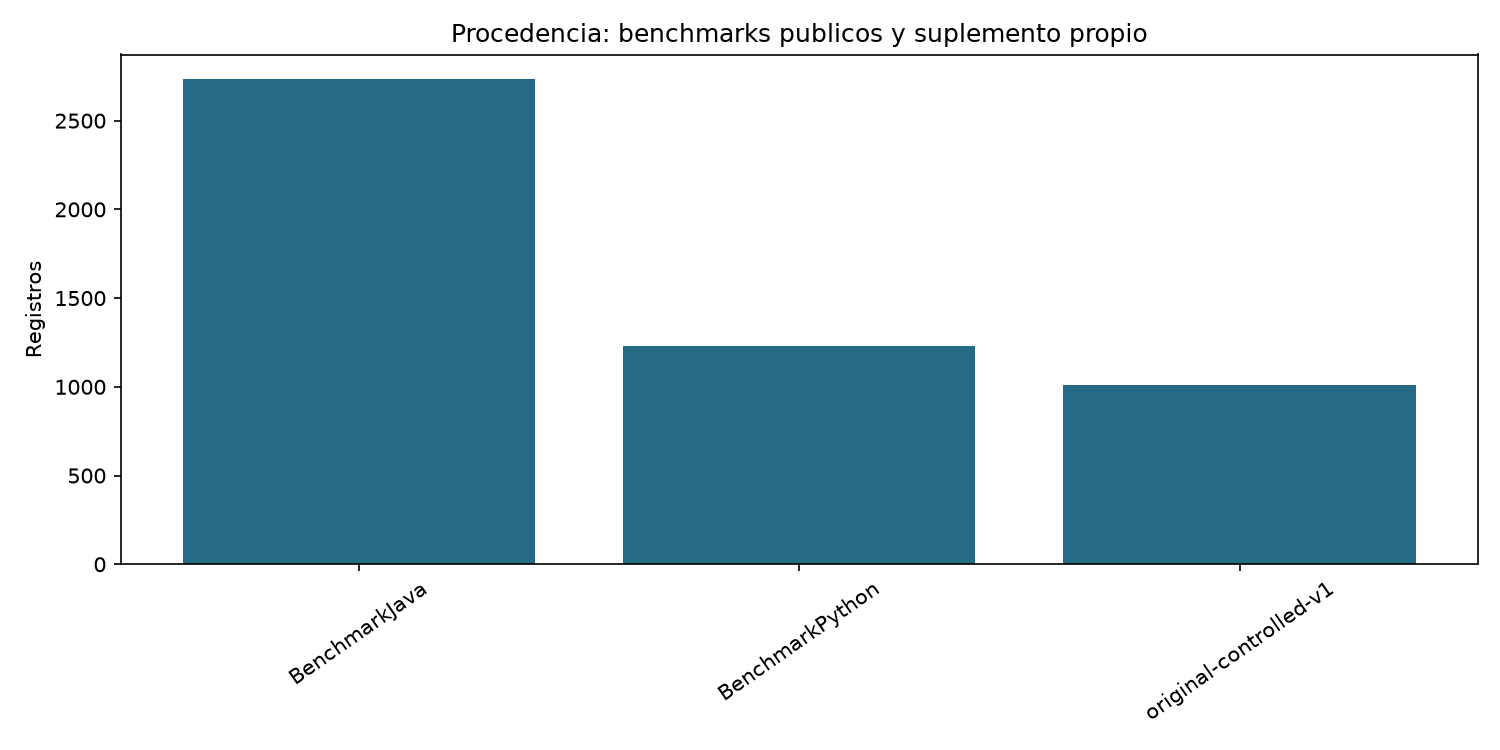

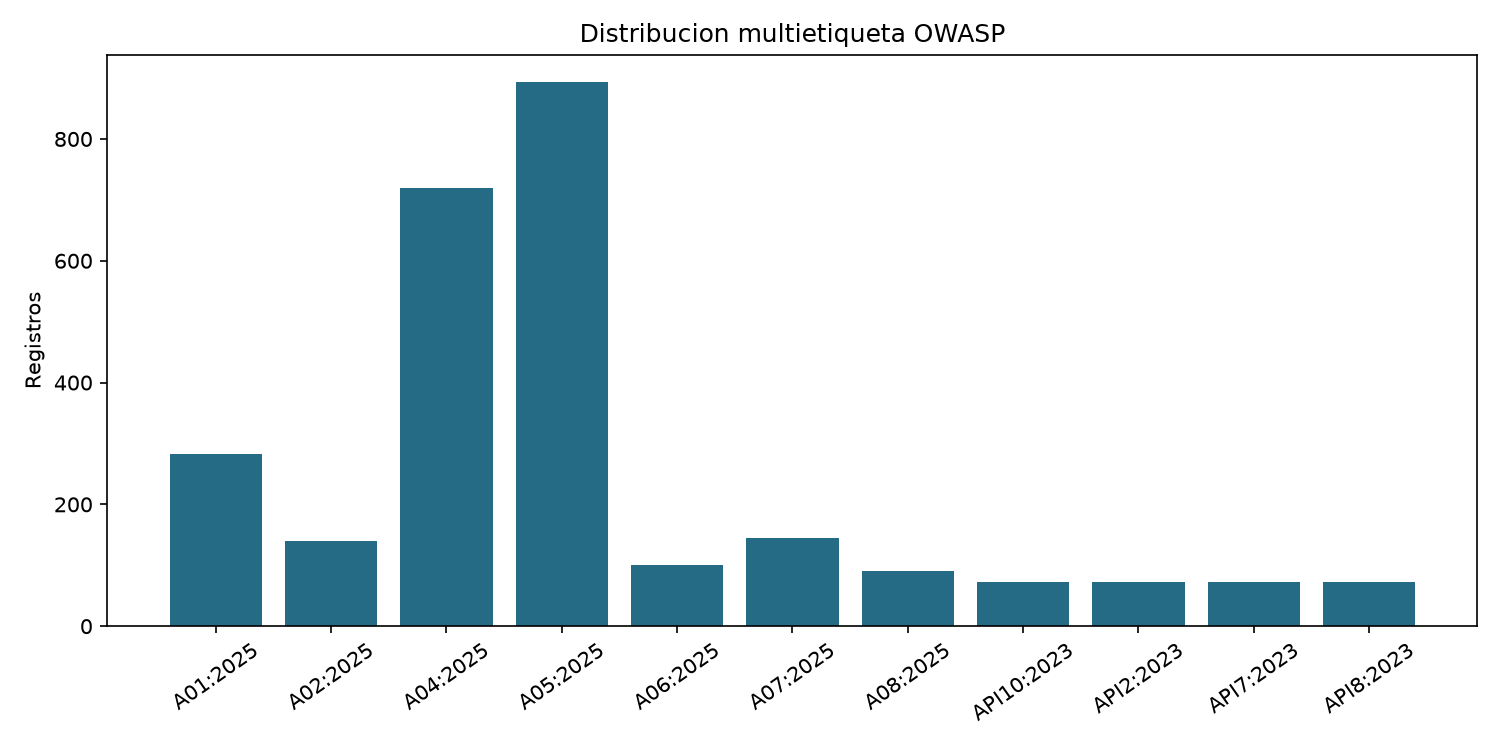

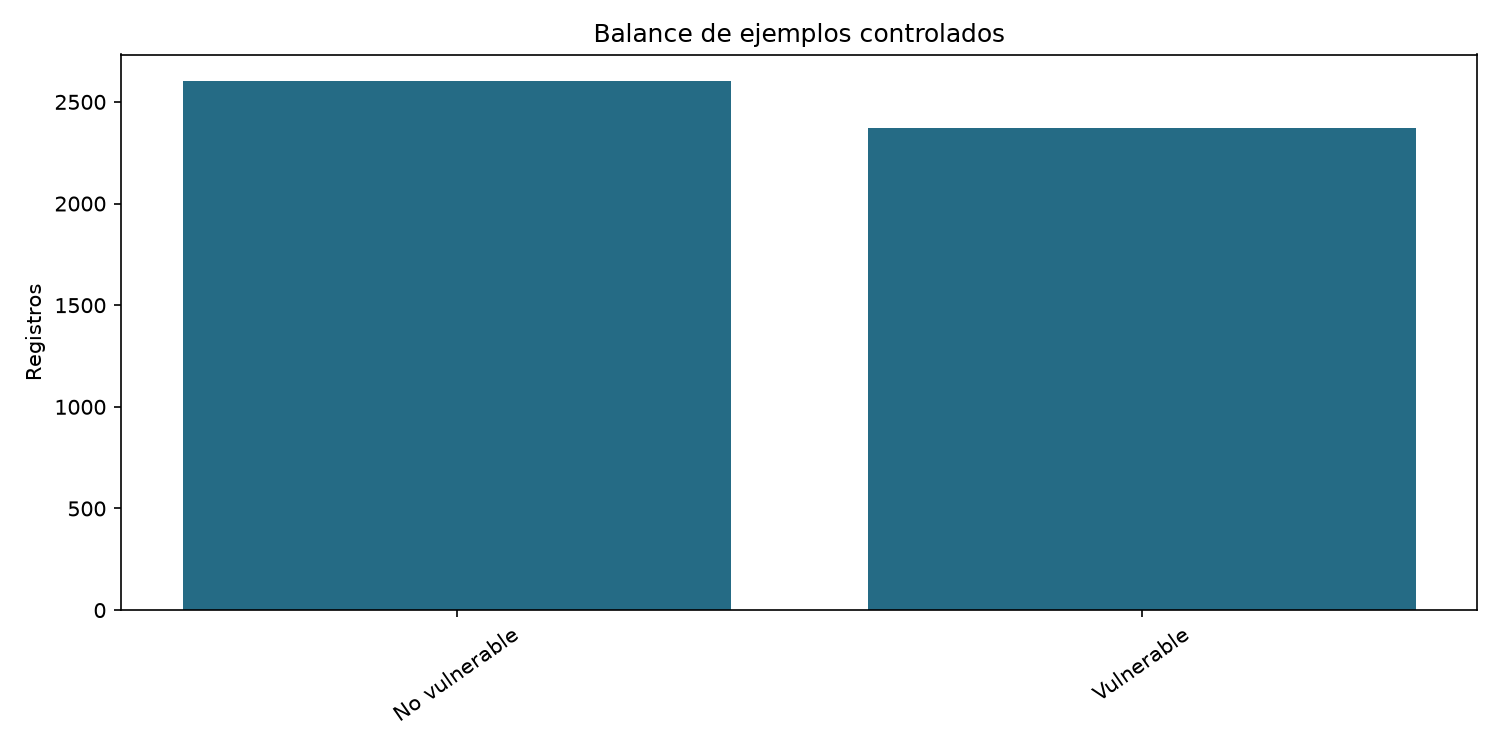

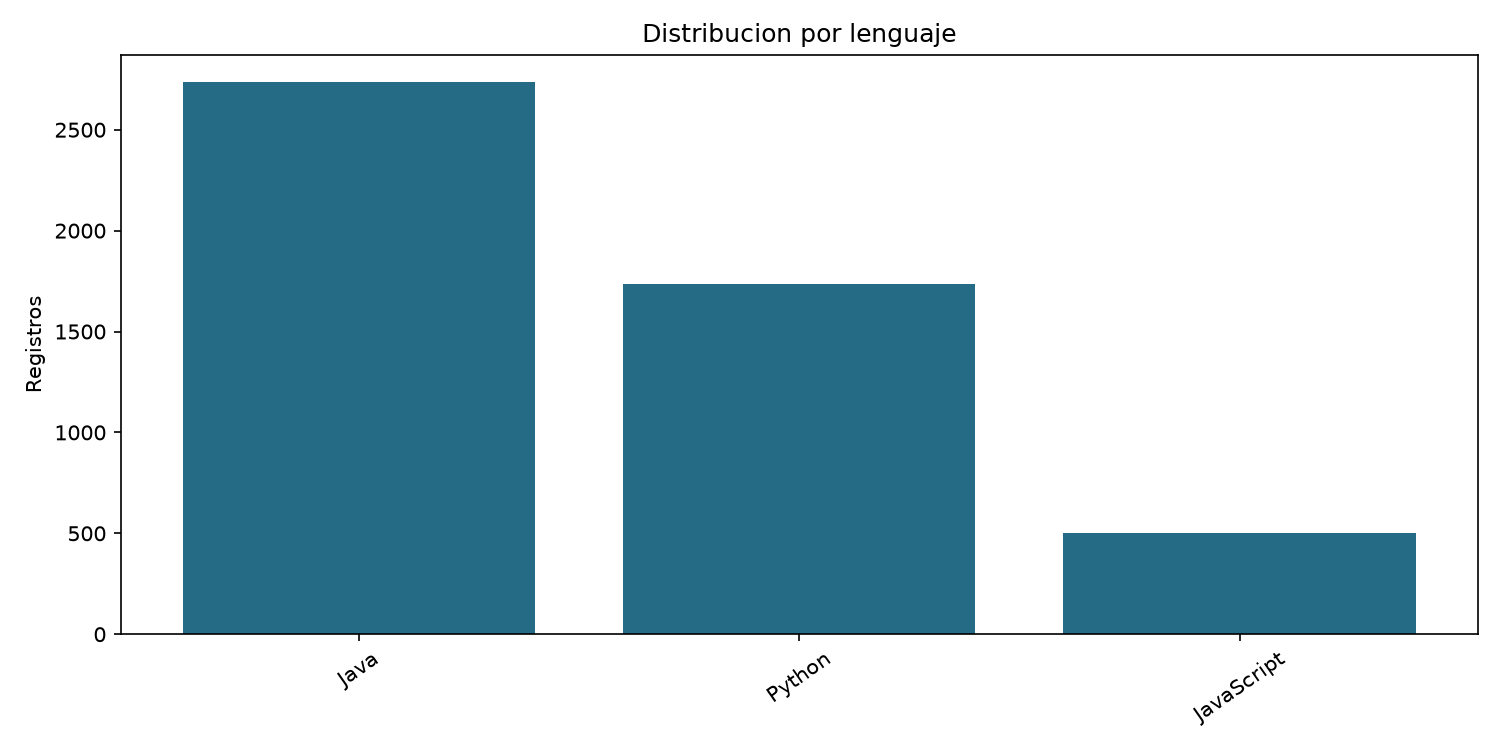

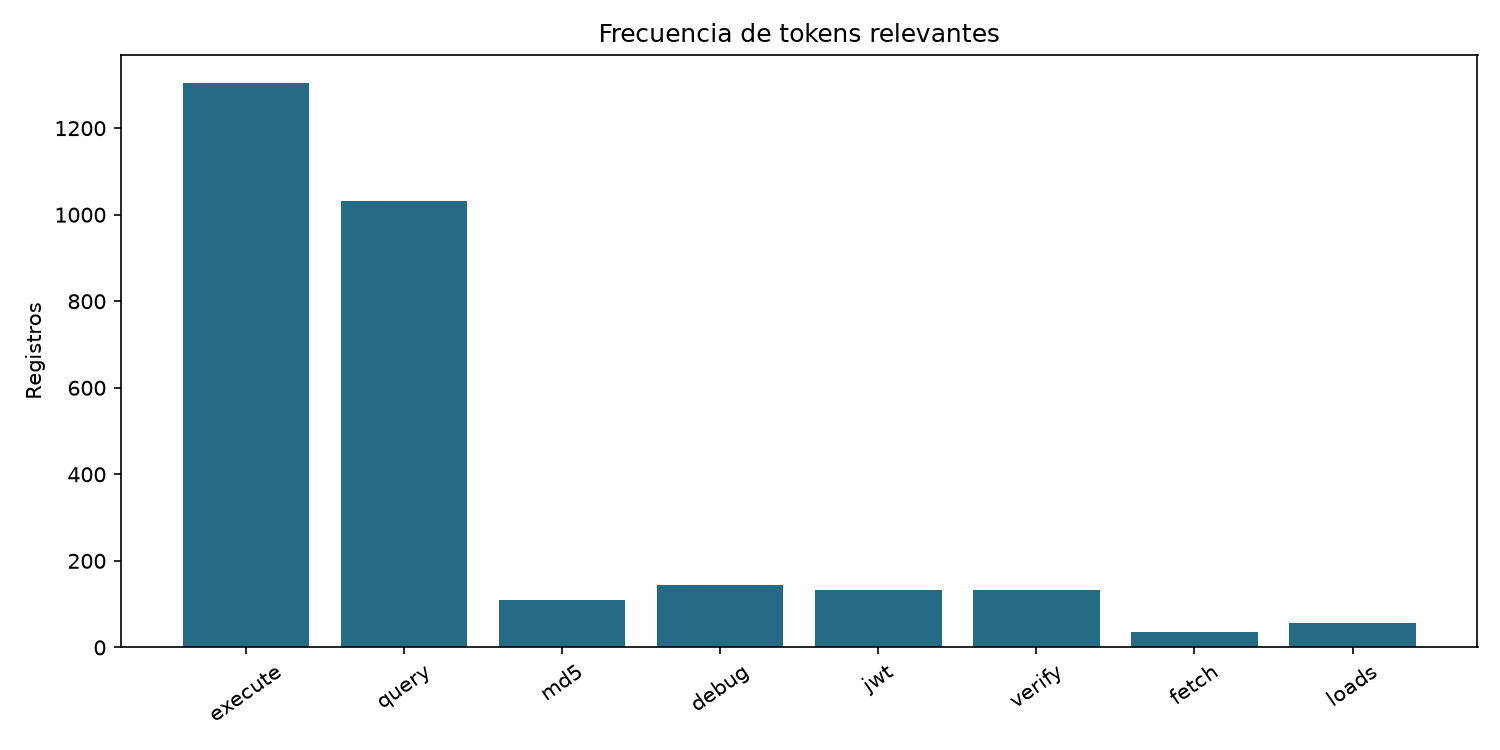

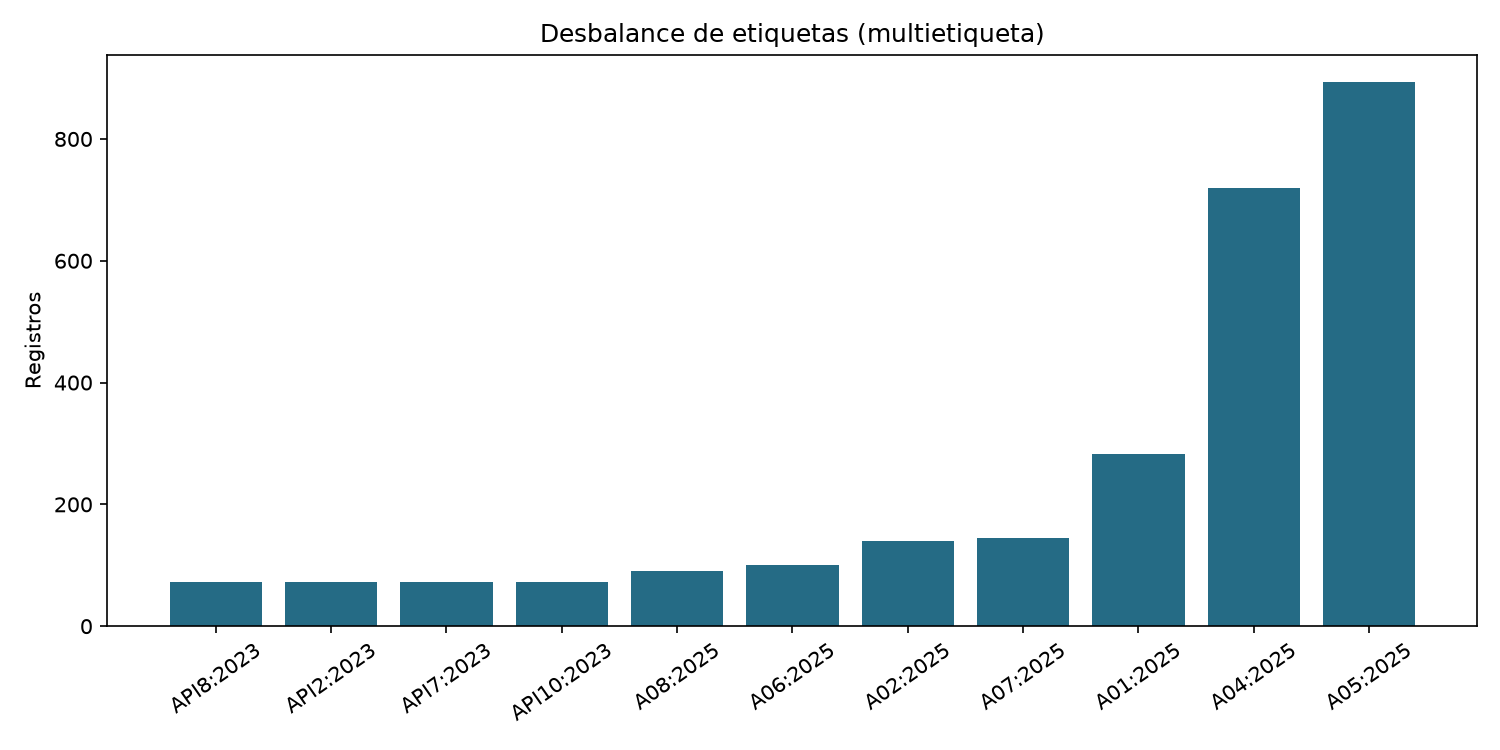

In [3]:
for name in ['fuentes','categorias','seguridad','lenguajes','patrones','desbalance']:
    display(Image(filename=str(ROOT / 'output/evaluation' / (name+'.png'))))

Los casos públicos dominan el corpus y contienen flujos más largos que los fragmentos propios. Las distribuciones por origen y por categoría son desiguales; una media global puede ocultar diferencias de desempeño. El enriquecimiento aumenta diversidad dentro de benchmarks y no demuestra representatividad de producción.